In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage as ndi
import cv2 as cv
import os

DATA_DIR = Path("Database_134_Angiograms")
IMG_ID = 1          # kullanılacak görüntü

In [4]:
def histogram_plot(image):
    histogram, bin_edges = np.histogram(image, bins=256, range=(0, 255))
    plt.figure()
    plt.title("Histogram")
    plt.xlabel("Pixel Value")
    plt.ylabel("Frequency")
    plt.plot(bin_edges[:-1], histogram, color='blue')
    plt.show()

In [5]:
def dice_score(mask, gt):
    # mask ve gt: damar = True
    tp = np.sum(mask & gt)
    return 2 * tp / (np.sum(mask) + np.sum(gt))

def error_image(mask, gt):
    # TP beyaz, FP kırmızı, FN mavi
    rgb = np.zeros(mask.shape + (3,), np.uint8)
    rgb[mask & gt] = (255, 255, 255)
    rgb[mask & ~gt] = (255, 60, 60)
    rgb[~mask & gt] = (60, 140, 255)
    return rgb

In [68]:
def histogram_plot(image):
    histogram, bin_edges = np.histogram(image, bins=256, range=(0, 255))
    plt.figure()
    plt.title("Histogram")
    plt.xlabel("Pixel Value")
    plt.ylabel("Frequency")
    plt.plot(bin_edges[:-1], histogram, color='blue')
    plt.show()

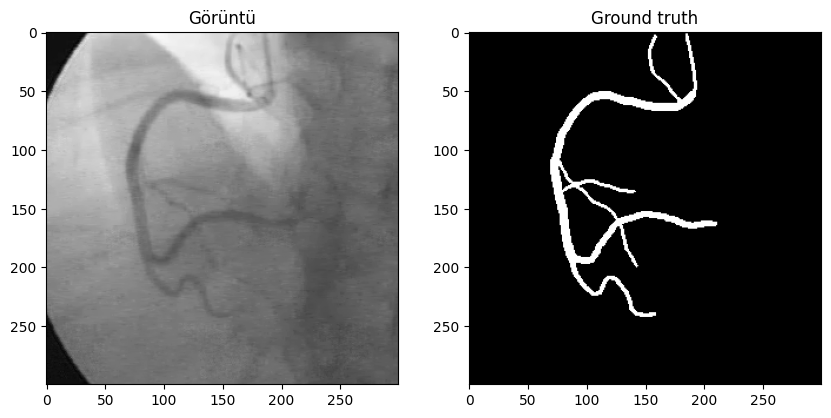

In [6]:
image = cv.imread(os.path.join(DATA_DIR, f"{IMG_ID}.pgm"), cv.IMREAD_GRAYSCALE)
gt = cv.imread(os.path.join(DATA_DIR, f"{IMG_ID}_gt.pgm"), cv.IMREAD_GRAYSCALE) > 127

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image, cmap='gray'); ax[0].set_title("Görüntü")
ax[1].imshow(gt, cmap='gray'); ax[1].set_title("Ground truth")
plt.show()

## 0. FOV MASKESİ
Köşelerdeki siyah kolimatör bölgesinin kenarı damar gibi algılanıyor. Threshold + erosion ile görüş alanı maskesi çıkarıyoruz.

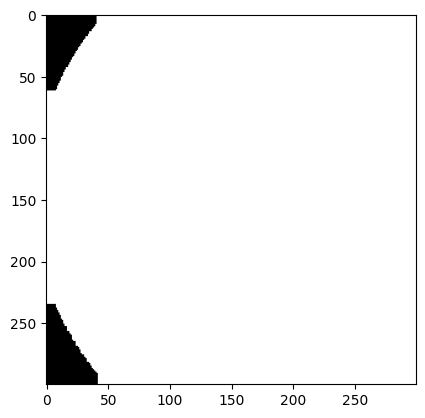

In [7]:
_, fov_mask = cv.threshold(image, 20, 255, cv.THRESH_BINARY)
fov_mask = cv.erode(fov_mask, kernel=np.ones((15, 15), np.uint8), iterations=1)
plt.imshow(fov_mask, cmap='gray')
plt.show()

## 1. SMOOTHING

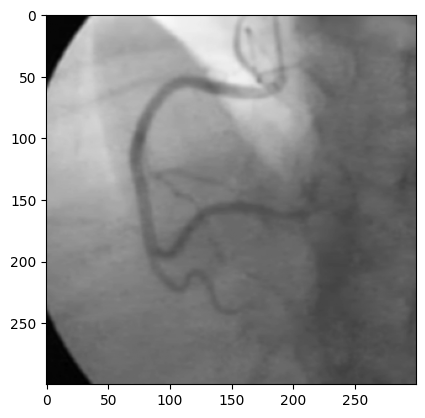

In [8]:
gaussian_filtered = ndi.gaussian_filter(image, sigma=1)
plt.imshow(gaussian_filtered, cmap='gray')
plt.show()

## 2. ARKA PLAN TAHMİNİ (max → min)
Damarlar açık zeminde koyu. Max filtresi (dilation) çekirdekten ince koyu yapıları siler, ardından aynı çekirdekle min filtresi (erosion) zemini eski hâline getirir. Sonuç: damarsız arka plan.
Çekirdek en kalın damardan büyük olmalı (11 / 15 / 21 / 31 denendi, en iyisi 21).

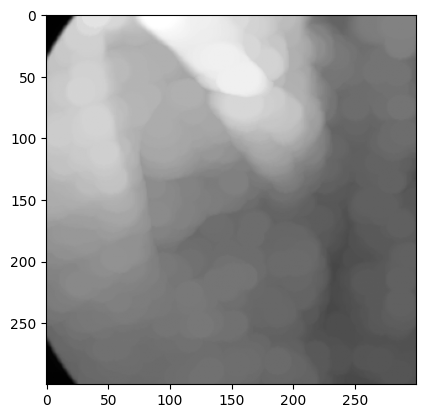

In [9]:
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (21, 21))
max_filtered = cv.dilate(gaussian_filtered, kernel)
plt.imshow(max_filtered, cmap='gray')
plt.show()

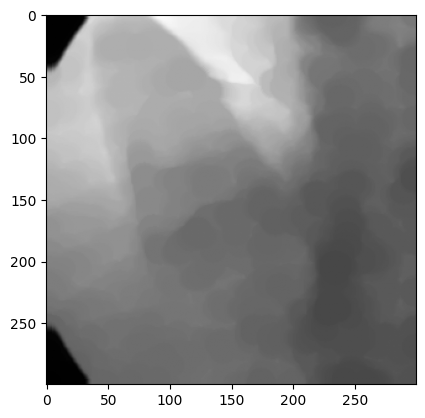

In [10]:
background = cv.erode(max_filtered, kernel)
plt.imshow(background, cmap='gray')
plt.show()

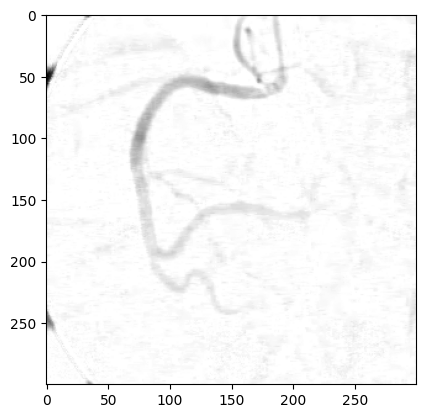

In [41]:
deneme = cv.subtract(background, image)
negative_image = 255 - deneme
normalized_image = cv.normalize(negative_image, None, 0, 255, cv.NORM_MINMAX)
plt.imshow(normalized_image, cmap='gray')
plt.show()

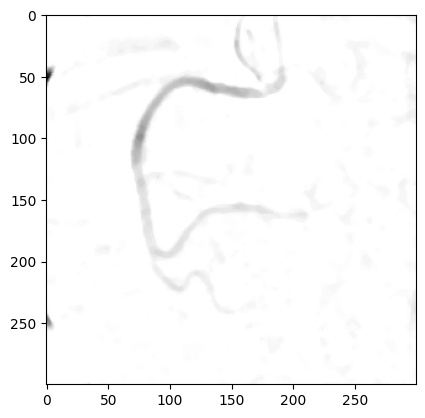

In [54]:
max_filtered = ndi.maximum_filter(normalized_image, size=3)
median_filtered = cv.medianBlur(max_filtered, 5)
plt.imshow(median_filtered, cmap='gray')
plt.show()

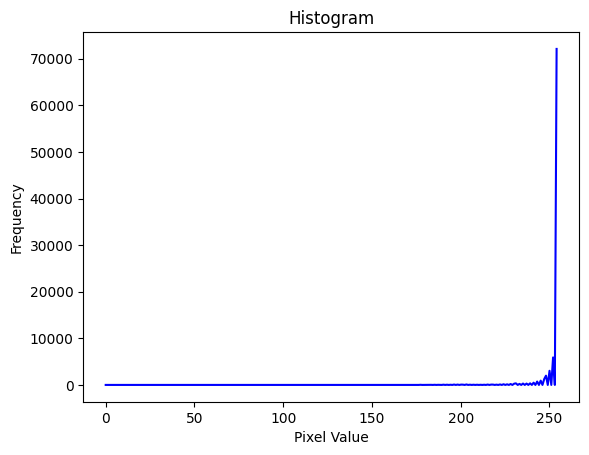

In [69]:
histogram_plot(median_filtered)

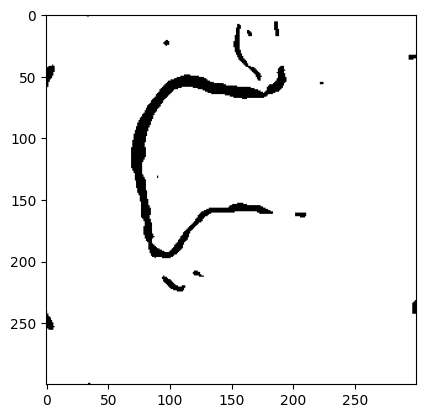

In [101]:
threshold_value = np.percentile(median_filtered, 3.5)  # Alt %5'lik dilim
adaptive_threshold = (median_filtered > threshold_value) * 255
plt.imshow(adaptive_threshold, cmap='gray')
plt.show()

In [92]:
print(adaptive_threshold.min(), adaptive_threshold.max(), adaptive_threshold.mean())

0 255 245.85683333333333


In [97]:
print(median_filtered.min(), median_filtered.max(), median_filtered.mean())

36 255 252.8966111111111


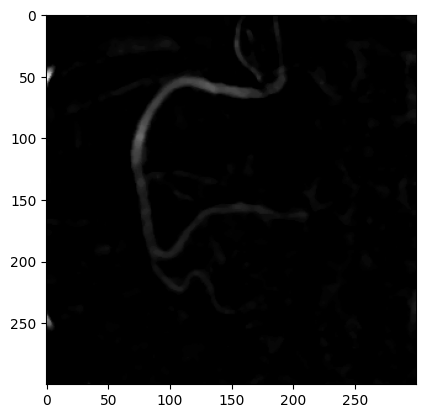

In [103]:
negative_median_filtered = 255 - median_filtered
plt.imshow(negative_median_filtered, cmap='gray')

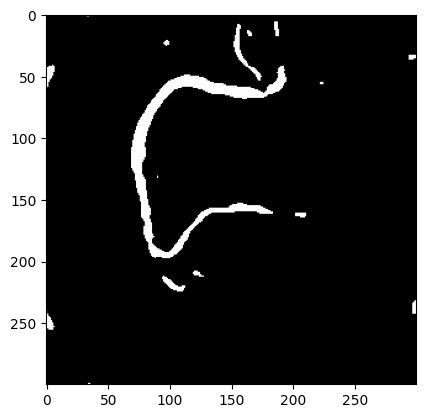

In [104]:
negative_adaptive_threshold = 255 - adaptive_threshold
plt.imshow(negative_adaptive_threshold, cmap='gray')

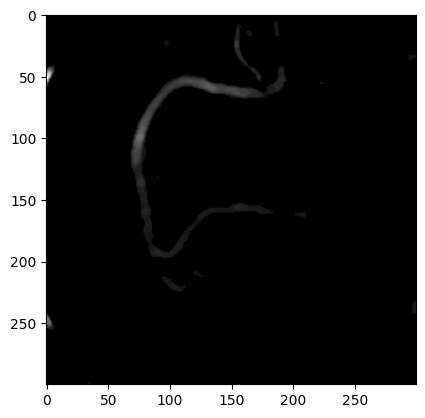

In [105]:
# if adaptive_threshold is 0, set it to the median_filtered value, else set it to 255 (white)
image_with_vessels = negative_median_filtered * negative_adaptive_threshold 
plt.imshow(image_with_vessels, cmap='gray')
plt.show()

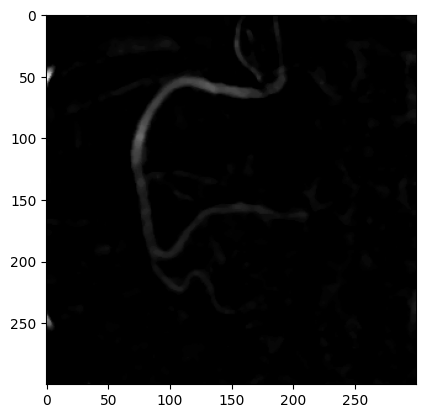

In [112]:
plt.imshow(negative_median_filtered, cmap='gray')
plt.show()

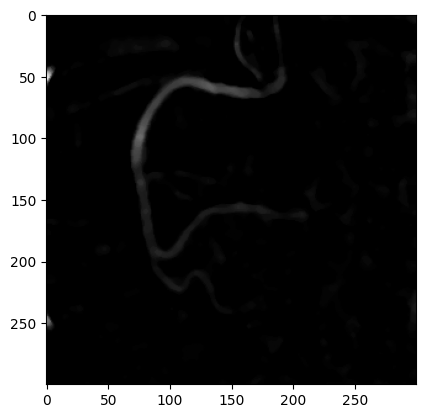

In [130]:
negative_median_filtered_median = cv.medianBlur(negative_median_filtered, 5)
plt.imshow(negative_median_filtered_median, cmap='gray')


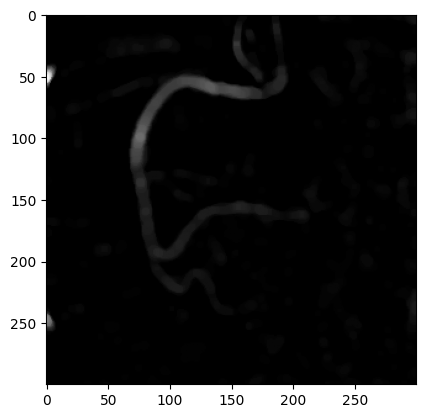

In [131]:
negative_median_filtered_median_max = ndi.maximum_filter(negative_median_filtered_median, size=3)
plt.imshow(negative_median_filtered_median_max, cmap='gray')
plt.show()

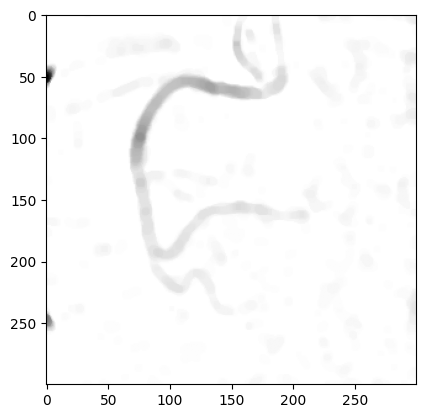

In [132]:
median_filtered_median_max = 255 - negative_median_filtered_median_max
plt.imshow(median_filtered_median_max, cmap='gray')

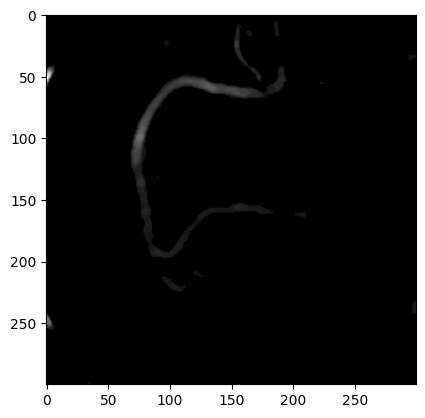

In [129]:
final_image =0.1*image_with_vessels + negative_median_filtered
plt.imshow(final_image, cmap='gray')
plt.show()

In [ ]:
erosion_kernel = np.ones((3, 3), np.uint8)
erosioned_image = cv.erode(negative_image, kernel=erosion_kernel, iterations=2)
dilation_kernel = np.ones((3, 3), np.uint8)
dilated_image = cv.dilate(erosioned_image, kernel=dilation_kernel, iterations=2)
plt.imshow(dilated_image, cmap='gray')
plt.show()

## 3. BLACK TOP-HAT (arka plan − görüntü)
Düzensiz aydınlatma gidiyor, damarlar parlak çıkıyor.

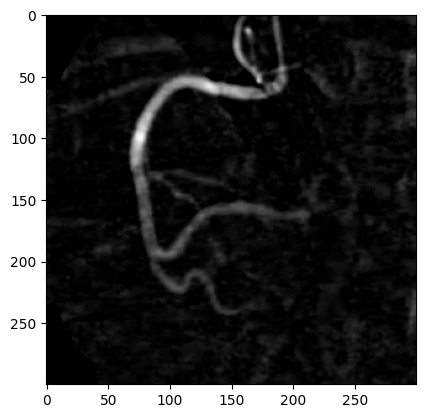

In [11]:
tophat = cv.subtract(background, gaussian_filtered)
tophat[fov_mask == 0] = 0
plt.imshow(tophat, cmap='gray')
plt.show()

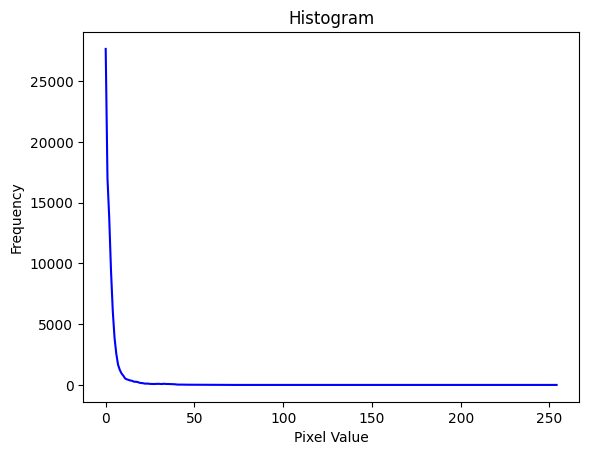

In [12]:
histogram_plot(tophat)

## 4. LAPLACIAN OF GAUSSIAN (çok ölçekli)
Gaussian + Laplacian, koyu bir damarın **merkezinde** pozitif tepe verir (Sobel ise iki kenar verir). Farklı kalınlıklar için birkaç sigma deneyip piksel başına maksimumu alıyoruz. `sigma**2` ile çarpmak ölçekleri karşılaştırılabilir yapıyor.

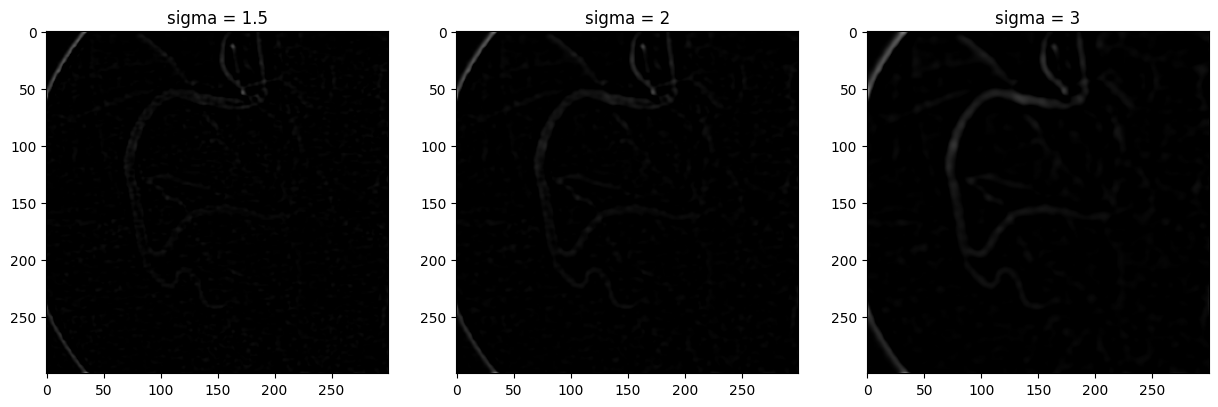

In [13]:
log_responses = []
for sigma in [1.5, 2, 3]:
    smoothed = ndi.gaussian_filter(image.astype(np.float64), sigma=sigma)
    laplacian_filtered = cv.Laplacian(smoothed, cv.CV_64F)
    log_responses.append(sigma**2 * laplacian_filtered)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, s, r in zip(ax, [1.5, 2, 3], log_responses):
    a.imshow(np.clip(r, 0, None), cmap='gray'); a.set_title(f"sigma = {s}")
plt.show()

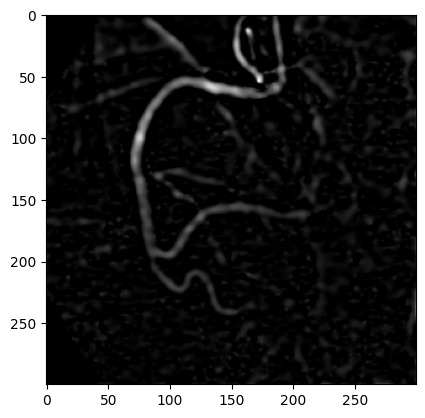

In [14]:
log_image = np.max(log_responses, axis=0)
log_image = np.clip(log_image, 0, None)   # negatif = açık yapı, damar değil
log_image[fov_mask == 0] = 0
plt.imshow(log_image, cmap='gray')
plt.show()

## 5. BİRLEŞTİRME
Top-hat kalın damarlarda, LoG ince dallarda güçlü. İkisini 0-1 aralığına normalize edip ortalamasını alıyoruz.

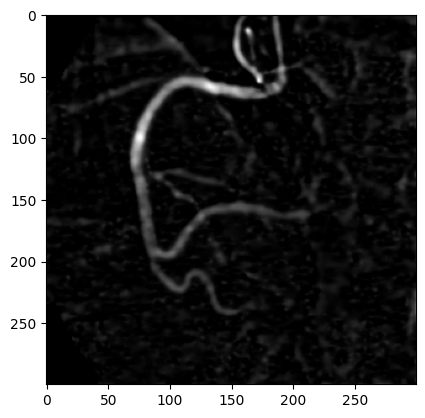

In [15]:
tophat_norm = cv.normalize(tophat.astype(np.float32), None, 0, 1, cv.NORM_MINMAX)
log_norm = cv.normalize(log_image.astype(np.float32), None, 0, 1, cv.NORM_MINMAX)
combined = 0.5 * tophat_norm + 0.5 * log_norm
plt.imshow(combined, cmap='gray')
plt.show()

## 6. THRESHOLD
Damarlar görüntünün ~%4-5'i. Tek bir global eşik (FOV içindeki 94.5. yüzdelik) ile başlıyoruz.

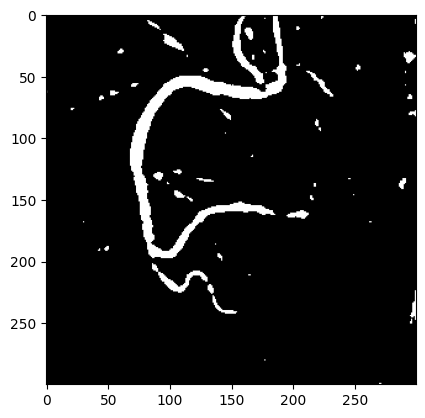

Dice: 0.718


In [16]:
fov_pixels = combined[fov_mask > 0]
threshold_value = np.percentile(fov_pixels, 94.5)
threshold_mask = (combined > threshold_value).astype(np.uint8) * 255
plt.imshow(threshold_mask, cmap='gray')
plt.show()
print("Dice:", round(dice_score(threshold_mask > 0, gt), 3))

## 7. HİSTEREZİS THRESHOLD (threshold + dilation)
- **Yüksek eşik (97. yüzdelik):** kesin damar pikselleri → tohum
- **Düşük eşik (92. yüzdelik):** aday pikseller

Tohumu tekrar tekrar dilate edip düşük eşik maskesiyle AND'liyoruz; değişim durunca bitiyor. Ana damara bağlı soluk dallar kalıyor, kopuk gürültü atılıyor.

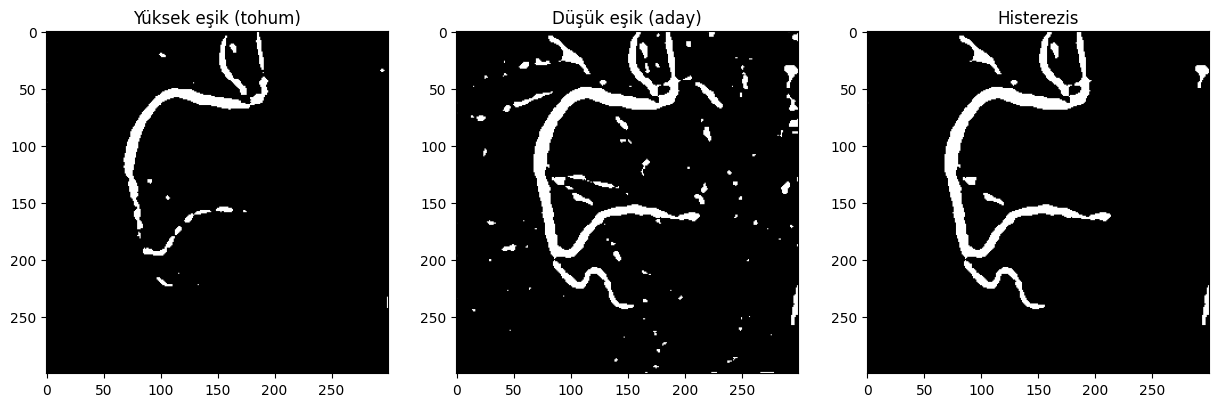

Dice: 0.715


In [17]:
high_value, low_value = np.percentile(fov_pixels, [97, 92])
strong = (combined > high_value).astype(np.uint8) * 255
weak = (combined > low_value).astype(np.uint8) * 255

hysteresis_mask = strong.copy()
while True:
    grown = cv.bitwise_and(cv.dilate(hysteresis_mask, np.ones((3, 3), np.uint8)), weak)
    if np.array_equal(grown, hysteresis_mask):
        break
    hysteresis_mask = grown

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(strong, cmap='gray'); ax[0].set_title("Yüksek eşik (tohum)")
ax[1].imshow(weak, cmap='gray'); ax[1].set_title("Düşük eşik (aday)")
ax[2].imshow(hysteresis_mask, cmap='gray'); ax[2].set_title("Histerezis")
plt.show()
print("Dice:", round(dice_score(hysteresis_mask > 0, gt), 3))

## 8. MORFOLOJİK SON İŞLEM
Maskede damar = **beyaz**, bu yüzden erosion/dilation sezgisel anlamında çalışıyor:
- median 3×3 → tuz-biber gürültüsü
- dilation → erosion (closing) → küçük kopukluklar

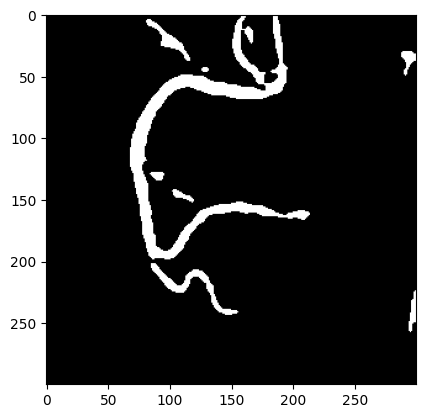

In [18]:
median_filtered = cv.medianBlur(hysteresis_mask, 3)
dilated_image = cv.dilate(median_filtered, kernel=np.ones((3, 3), np.uint8), iterations=1)
final_mask = cv.erode(dilated_image, kernel=np.ones((3, 3), np.uint8), iterations=1)
plt.imshow(final_mask, cmap='gray')
plt.show()

## 9. DEĞERLENDİRME

Threshold (tek eşik)         Dice = 0.718
Histerezis                   Dice = 0.715
Final (median + closing)     Dice = 0.717


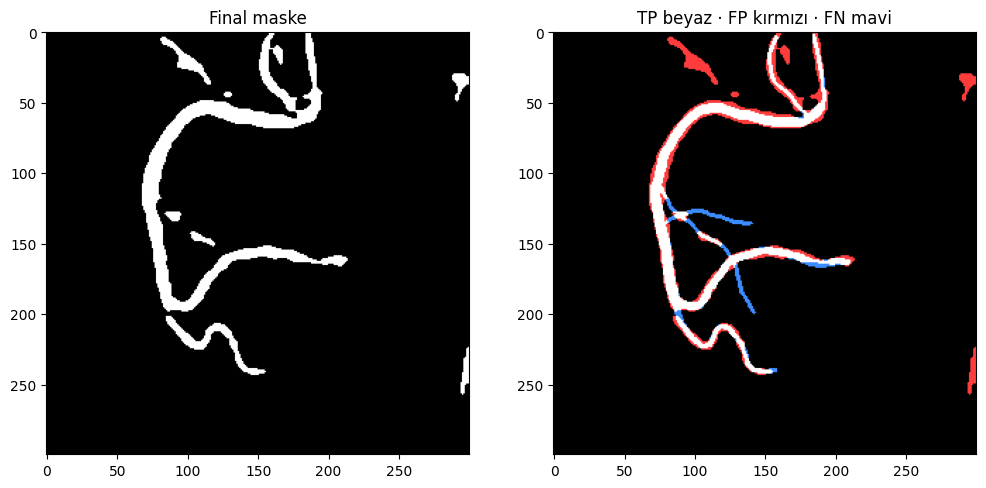

In [19]:
steps = {
    "Threshold (tek eşik)": threshold_mask,
    "Histerezis": hysteresis_mask,
    "Final (median + closing)": final_mask,
}
for name, m in steps.items():
    print(f"{name:28s} Dice = {dice_score(m > 0, gt):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(final_mask, cmap='gray'); ax[0].set_title("Final maske")
ax[1].imshow(error_image(final_mask > 0, gt)); ax[1].set_title("TP beyaz · FP kırmızı · FN mavi")
plt.show()

## 10. TÜM VERİ SETİ (134 görüntü)
Yukarıdaki adımları tek fonksiyonda topluyoruz ve önceki pipeline ile karşılaştırıyoruz.

In [20]:
def old_pipeline(image):
    # blood_vessel_segmentation.ipynb hücre 4-10
    gaussian_filtered = ndi.gaussian_filter(image, sigma=1)
    contrast_image = cv.convertScaleAbs(gaussian_filtered, alpha=1.5, beta=0)
    max_filtered = ndi.maximum_filter(contrast_image, size=5)
    median_filtered = cv.medianBlur(max_filtered, 5)
    adaptive_threshold = cv.adaptiveThreshold(median_filtered, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY_INV, 31, 8)
    negative_image = 255 - adaptive_threshold
    erosioned_image = cv.erode(negative_image, kernel=np.ones((3, 3), np.uint8), iterations=2)
    dilated_image = cv.dilate(erosioned_image, kernel=np.ones((2, 2), np.uint8), iterations=2)
    erosioned_image = cv.erode(dilated_image, kernel=np.ones((2, 2), np.uint8), iterations=2)
    return erosioned_image == 0


def new_pipeline(image, kernel_size=21, sigmas=(1.5, 2, 3), high=97, low=92):
    _, fov_mask = cv.threshold(image, 20, 255, cv.THRESH_BINARY)
    fov_mask = cv.erode(fov_mask, kernel=np.ones((15, 15), np.uint8), iterations=1)

    gaussian_filtered = ndi.gaussian_filter(image, sigma=1)
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (kernel_size, kernel_size))
    background = cv.erode(cv.dilate(gaussian_filtered, kernel), kernel)
    tophat = cv.subtract(background, gaussian_filtered)
    tophat[fov_mask == 0] = 0

    log_responses = []
    for sigma in sigmas:
        smoothed = ndi.gaussian_filter(image.astype(np.float64), sigma=sigma)
        log_responses.append(sigma**2 * cv.Laplacian(smoothed, cv.CV_64F))
    log_image = np.clip(np.max(log_responses, axis=0), 0, None)
    log_image[fov_mask == 0] = 0

    combined = 0.5 * cv.normalize(tophat.astype(np.float32), None, 0, 1, cv.NORM_MINMAX) \
             + 0.5 * cv.normalize(log_image.astype(np.float32), None, 0, 1, cv.NORM_MINMAX)

    high_value, low_value = np.percentile(combined[fov_mask > 0], [high, low])
    strong = (combined > high_value).astype(np.uint8) * 255
    weak = (combined > low_value).astype(np.uint8) * 255
    mask = strong.copy()
    while True:
        grown = cv.bitwise_and(cv.dilate(mask, np.ones((3, 3), np.uint8)), weak)
        if np.array_equal(grown, mask):
            break
        mask = grown

    mask = cv.medianBlur(mask, 3)
    mask = cv.erode(cv.dilate(mask, np.ones((3, 3), np.uint8)), np.ones((3, 3), np.uint8))
    return mask > 0

Eski pipeline  Dice = 0.438 ± 0.103
Yeni pipeline  Dice = 0.703 ± 0.062


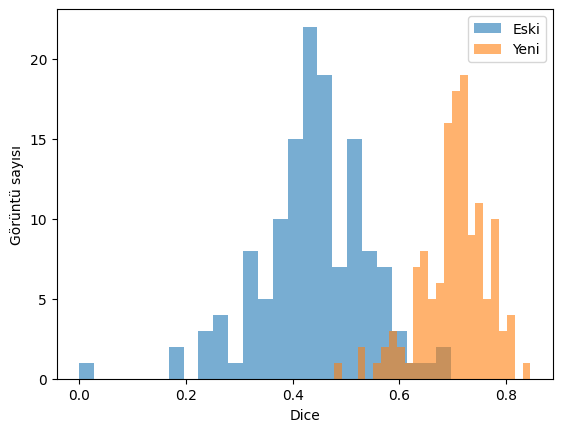

In [21]:
old_scores, new_scores = [], []
for i in range(1, 135):
    img_i = cv.imread(os.path.join(DATA_DIR, f"{i}.pgm"), cv.IMREAD_GRAYSCALE)
    gt_i = cv.imread(os.path.join(DATA_DIR, f"{i}_gt.pgm"), cv.IMREAD_GRAYSCALE) > 127
    old_scores.append(dice_score(old_pipeline(img_i), gt_i))
    new_scores.append(dice_score(new_pipeline(img_i), gt_i))

print(f"Eski pipeline  Dice = {np.mean(old_scores):.3f} ± {np.std(old_scores):.3f}")
print(f"Yeni pipeline  Dice = {np.mean(new_scores):.3f} ± {np.std(new_scores):.3f}")

plt.hist(old_scores, bins=25, alpha=0.6, label="Eski")
plt.hist(new_scores, bins=25, alpha=0.6, label="Yeni")
plt.xlabel("Dice"); plt.ylabel("Görüntü sayısı"); plt.legend()
plt.show()

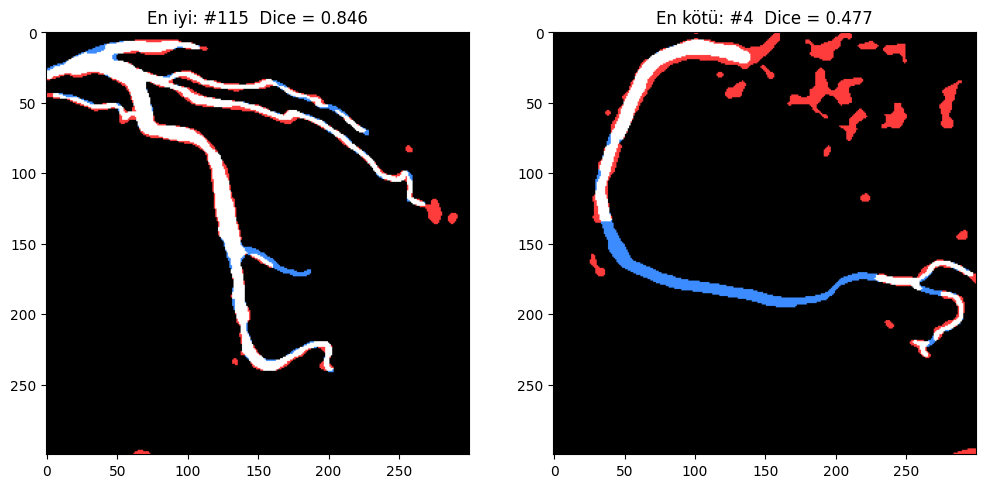

In [22]:
worst, best = np.argsort(new_scores)[[0, -1]] + 1
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, idx, name in [(ax[0], best, "En iyi"), (ax[1], worst, "En kötü")]:
    img_i = cv.imread(os.path.join(DATA_DIR, f"{idx}.pgm"), cv.IMREAD_GRAYSCALE)
    gt_i = cv.imread(os.path.join(DATA_DIR, f"{idx}_gt.pgm"), cv.IMREAD_GRAYSCALE) > 127
    a.imshow(error_image(new_pipeline(img_i), gt_i))
    a.set_title(f"{name}: #{idx}  Dice = {new_scores[idx - 1]:.3f}")
plt.show()